In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import statsmodels.formula.api as smf


In [17]:
calendar = pd.read_csv(r"C:\Users\sanou\Documents\projet data science\bd\calendar.csv")
sells = pd.read_csv(r"C:\Users\sanou\Documents\projet data science\bd\sales_train_validation.csv")
price = pd.read_csv(r"C:\Users\sanou\Documents\projet data science\bd\sell_prices.csv")


In [18]:
#Statistiques descriptives

#Calendar
calendar.head()
calendar.shape
calendar.dtypes
calendar.isna().sum()
calendar.duplicated(subset=["d"]).sum()


#Ventes
sells.head()
sells.shape
sells.dtypes
sells.isna().sum()
sells.duplicated(subset=["item_id", "store_id"]).sum()



#Prix
price.head()
price.shape
price.dtypes
price.isna().sum()
price.duplicated(subset=["item_id", "store_id", "wm_yr_wk"]).sum()



np.int64(0)

In [19]:
#Réglage de la base Sells car trop de variables
# On prend seulement 100 lignes pour tester
sells_test = sells.head(100)

# Colonnes qui identifient les produits et magasins
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]

# Transformation du format large au format long
sells_long = pd.melt(
    sells_test,
    id_vars=id_cols,
    var_name="d",
    value_name="ventes"
)

# Vérification
print(sells_long.shape)
print(sells_long.head())

(191300, 8)
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id    d  ventes  
0       CA  d_1       0  
1       CA  d_1       0  
2       CA  d_1       0  
3       CA  d_1       0  
4       CA  d_1       0  


In [20]:
price.columns

Index(['store_id', 'item_id', 'wm_yr_wk', 'sell_price'], dtype='object')

In [21]:
#Jointure 
new_sells = pd.merge(
    sells_long,
    calendar[["d", "date", "wm_yr_wk"]],
    on="d",
    how="left",
    validate="many_to_one"
)

base = pd.merge(
    new_sells,
    price,
    on=["item_id", "store_id", "wm_yr_wk"],
    how="left",
    validate="many_to_one"
)

In [25]:
base["sell_price"].isna().sum()
base.loc[base["sell_price"].isna(), "ventes"].describe()

count    30940.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: ventes, dtype: float64

In [26]:
base_prix = base.dropna(subset=["sell_price"]).copy()

print(base_prix.shape)

(160360, 11)


In [33]:
base_prix["CA"] = base_prix["ventes"] * base_prix["sell_price"]

# Chiffre d'affaires total
ca_total = base_prix["CA"].sum()
print(ca_total)

# Top 10 des produits
top_produits = (
    base_prix.groupby("item_id")["CA"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_produits)

ca_magasin = (
    base_prix.groupby("store_id")["CA"]
    .sum()
    .sort_values(ascending=False)
)

print(ca_magasin)

726414.24
item_id
HOBBIES_1_078    46570.49
HOBBIES_1_064    37841.22
HOBBIES_1_099    27396.72
HOBBIES_1_055    27034.08
HOBBIES_1_085    26348.80
HOBBIES_1_089    24634.59
HOBBIES_1_029    23518.30
HOBBIES_1_050    19057.26
HOBBIES_1_037    18747.26
HOBBIES_1_086    16805.10
Name: CA, dtype: float64
store_id
CA_1    726414.24
Name: CA, dtype: float64


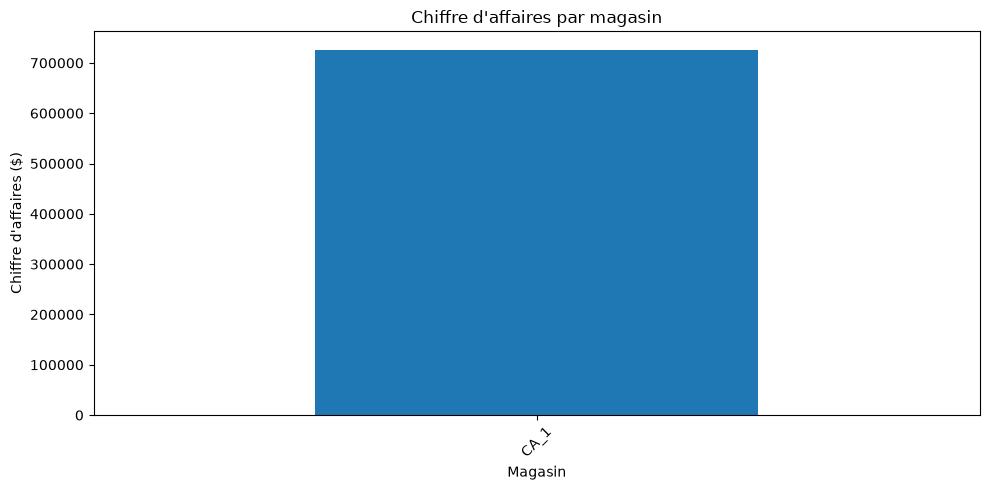

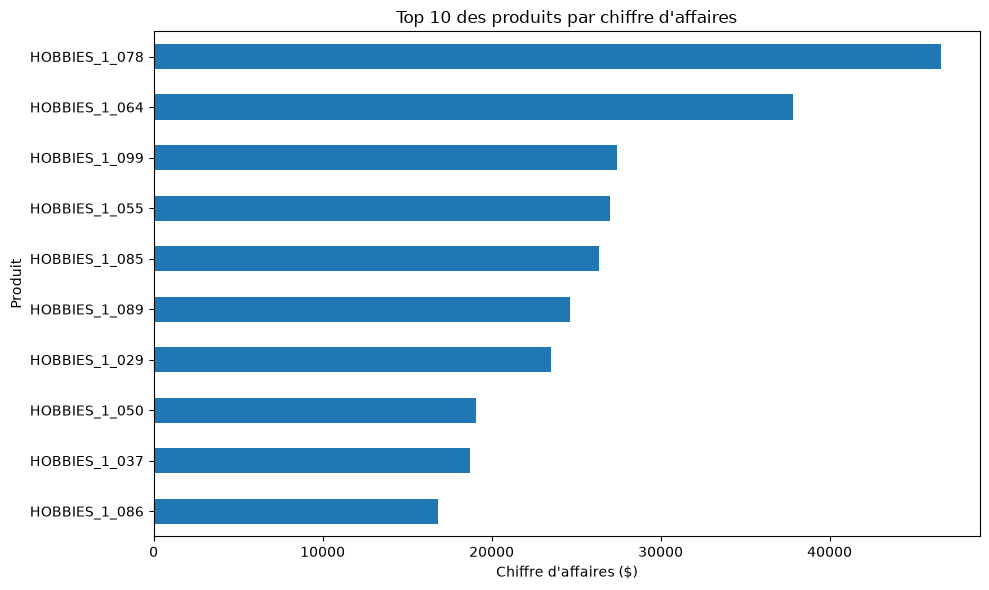

In [34]:
# CA par magasin
ca_magasin = (
    base_prix.groupby("store_id")["CA"]
    .sum()
    .sort_values(ascending=False)
)

ca_magasin.plot(kind="bar", figsize=(10, 5))
plt.title("Chiffre d'affaires par magasin")
plt.xlabel("Magasin")
plt.ylabel("Chiffre d'affaires ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Top 10 des produits
top_produits.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title("Top 10 des produits par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires ($)")
plt.ylabel("Produit")
plt.tight_layout()
plt.show()

            item_id store_id       date  ventes  ventes_j_7  ventes_j_28
0     HOBBIES_1_001     CA_1 2011-01-29       0         NaN          NaN
100   HOBBIES_1_001     CA_1 2011-01-30       0         NaN          NaN
200   HOBBIES_1_001     CA_1 2011-01-31       0         NaN          NaN
300   HOBBIES_1_001     CA_1 2011-02-01       0         NaN          NaN
400   HOBBIES_1_001     CA_1 2011-02-02       0         NaN          NaN
500   HOBBIES_1_001     CA_1 2011-02-03       0         NaN          NaN
600   HOBBIES_1_001     CA_1 2011-02-04       0         NaN          NaN
700   HOBBIES_1_001     CA_1 2011-02-05       0         0.0          NaN
800   HOBBIES_1_001     CA_1 2011-02-06       0         0.0          NaN
900   HOBBIES_1_001     CA_1 2011-02-07       0         0.0          NaN
1000  HOBBIES_1_001     CA_1 2011-02-08       0         0.0          NaN
1100  HOBBIES_1_001     CA_1 2011-02-09       0         0.0          NaN
1200  HOBBIES_1_001     CA_1 2011-02-10       0    

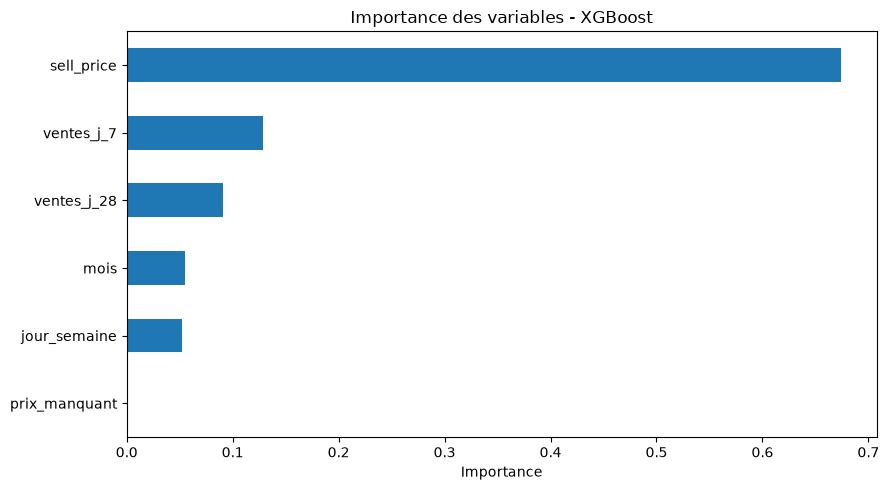

In [42]:
#Modèle XGBOOST


# Conversion de la date
base["date"] = pd.to_datetime(base["date"])

# Tri chronologique
base = base.sort_values(["item_id", "store_id", "date"]).copy()

# Variables calendaires
base["jour_semaine"] = base["date"].dt.dayofweek
base["mois"] = base["date"].dt.month

# Ventes passées par produit et magasin
groupe = base.groupby(["item_id", "store_id"])["ventes"]

base["ventes_j_7"] = groupe.shift(7)
base["ventes_j_28"] = groupe.shift(28)

# Vérification
print(base[[
    "item_id", "store_id", "date",
    "ventes", "ventes_j_7", "ventes_j_28"
]].head(35))

# On travaille sur une copie
df_ml = base.copy()

# On supprime les 28 premiers jours de chaque produit-magasin
# car ils n'ont pas suffisamment d'historique
df_ml = df_ml.dropna(subset=["ventes_j_7", "ventes_j_28"])

# Indicateur de prix manquant
df_ml["prix_manquant"] = df_ml["sell_price"].isna().astype(int)

# Variables explicatives
features = [
    "sell_price",
    "prix_manquant",
    "jour_semaine",
    "mois",
    "ventes_j_7",
    "ventes_j_28"
]

target = "ventes"

# Les 28 derniers jours serviront au test
date_limite = df_ml["date"].max() - pd.Timedelta(days=28)

train = df_ml[df_ml["date"] <= date_limite]
test = df_ml[df_ml["date"] > date_limite]

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("Train :", X_train.shape)
print("Test :", X_test.shape)


modele = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)

modele.fit(X_train, y_train)

predictions = modele.predict(X_test)
predictions = np.clip(predictions, 0, None)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

# Prévision naïve : mêmes ventes que 7 jours auparavant
mae_naive = mean_absolute_error(y_test, X_test["ventes_j_7"])

print("MAE XGBoost :", round(mae, 3))
print("RMSE XGBoost :", round(rmse, 3))
print("MAE naïve :", round(mae_naive, 3))

importance = pd.Series(
    modele.feature_importances_,
    index=X_train.columns
).sort_values()

importance.plot(kind="barh", figsize=(9, 5))
plt.title("Importance des variables - XGBoost")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [47]:
# 1. Identifier les produits avec des variations de prix
variation_prix = (
    base_prix.groupby(["item_id", "store_id"])
    .agg(
        nb_prix=("sell_price", "nunique"),
        nb_ventes=("ventes", "sum")
    )
    .query("nb_prix >= 5 and nb_ventes > 0")
    .sort_values("nb_prix", ascending=False)
)

print(variation_prix.head(10))

if variation_prix.empty:
    raise ValueError("Aucun produit ne correspond aux critères.")

# 2. Sélectionner un produit et un magasin
item, magasin = variation_prix.index[0]

df_elasticite = base_prix[
    (base_prix["item_id"] == item) &
    (base_prix["store_id"] == magasin) &
    (base_prix["ventes"] > 0) &
    (base_prix["sell_price"] > 0)
].copy()

# 3. Créer les variables nécessaires
df_elasticite["date"] = pd.to_datetime(df_elasticite["date"])
df_elasticite["mois"] = df_elasticite["date"].dt.month

df_elasticite["log_ventes"] = np.log(df_elasticite["ventes"])
df_elasticite["log_prix"] = np.log(df_elasticite["sell_price"])

# 4. Estimer l'élasticité-prix
regression = smf.ols(
    "log_ventes ~ log_prix + C(mois)",
    data=df_elasticite
).fit(cov_type="HC3")

# 5. Afficher les résultats
print("Produit :", item)
print("Magasin :", magasin)
print("Élasticité estimée :", round(regression.params["log_prix"], 3))
print("P-value :", round(regression.pvalues["log_prix"], 4))

                        nb_prix  nb_ventes
item_id       store_id                    
HOBBIES_1_098 CA_1            6        866
HOBBIES_1_099 CA_1            6       1847
Produit : HOBBIES_1_098
Magasin : CA_1
Élasticité estimée : 0.116
P-value : 0.7798


In [50]:
donnees_app = (
    base_prix.groupby(["item_id", "store_id"])
    .agg(
        prix_actuel=("sell_price", "last"),
        ventes_moyennes=("ventes", "mean")
    )
    .reset_index()
)

donnees_app.to_csv(
    r"C:\Users\sanou\Documents\projet data science\donnees_app.csv",
    index=False
)

print("Exportation réussie !")

Exportation réussie !
